# 01 – Missing and Erroneous Values

Objective: identify and treat missing values and erroneous data so the dataset is ready for modelling. Every decision is justified with evidence and evaluated in terms of its impact on a future regression model.

Input: data/processed/listings_00.parquet (output of notebook 00).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Consistent visual style
sns.set_theme(style="whitegrid", palette="colorblind", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

PERIOD_MAP = {"201803": "Q1 2018", "201806": "Q2 2018", "201809": "Q3 2018", "201812": "Q4 2018"}

df = pd.read_parquet("../data/processed/listings_00.parquet")

print(f"Loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")

Loaded: 94,815 rows × 41 columns


## 1. Missing values overview

,Missing,% of total
CONSTRUCTIONYEAR,55873,58.93
FLATLOCATIONID,6387,6.74
FLOORCLEAN,3846,4.06
CADASTRALQUALITYID,1,0.00


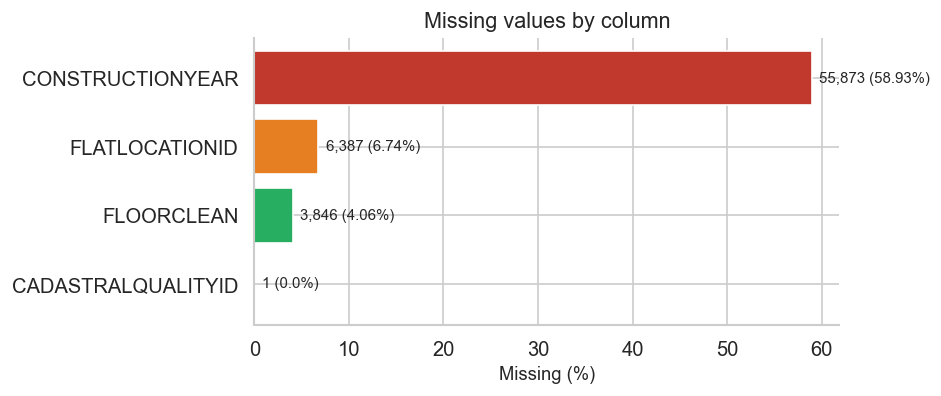

In [2]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({"Missing": missing, "% of total": missing_pct})
display(missing_df)

# Bar chart of missing percentages
fig, ax = plt.subplots(figsize=(8, 3.5))
severity_colors = ["#c0392c" if p > 50 else "#e67e22" if p > 5 else "#27ae60" for p in missing_pct]
bars = ax.barh(missing_pct.index[::-1], missing_pct.values[::-1],
               color=severity_colors[::-1], edgecolor="white")
for i, (v, c) in enumerate(zip(missing_pct.values[::-1], missing.values[::-1])):
    ax.text(v + 0.8, i, f"{c:,} ({v}%)", va="center", fontsize=9)
ax.set_xlabel("Missing (%)")
ax.set_title("Missing values by column")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Only 4 columns have missing values. The target variable PRICE and all binary features are 100% complete, so no imputation is needed on the target side.

Each missing column requires a different strategy depending on the percentage of missing data, whether missingness is random or informative, and whether a reliable alternative exists in the dataset.

### 1.1 CONSTRUCTIONYEAR — 59% missing

This column is self-reported by the listing agent and missing for more than half the dataset. It also contains erroneous values. However, the cadastral alternative CADCONSTRUCTIONYEAR is 100% complete and comes from an official source (Spanish Cadastre).

In [3]:
cy = df["CONSTRUCTIONYEAR"].dropna()
print(f"Non-null values: {len(cy):,} / {len(df):,} ({len(cy)/len(df):.1%})")
print(f"Range: {cy.min():.0f} – {cy.max():.0f}")

suspicious = cy[(cy < 1800) | (cy > 2020)]
print(f"\nSuspicious values (year < 1800 or > 2020): {len(suspicious)} rows")
print(f"Examples: {suspicious.head(10).tolist()}")

Non-null values: 38,942 / 94,815 (41.1%)
Range: 1 – 2291

Suspicious values (year < 1800 or > 2020): 43 rows
Examples: [1692.0, 1623.0, 1623.0, 1627.0, 7.0, 1056.0, 173.0, 1780.0, 198.0, 50.0]


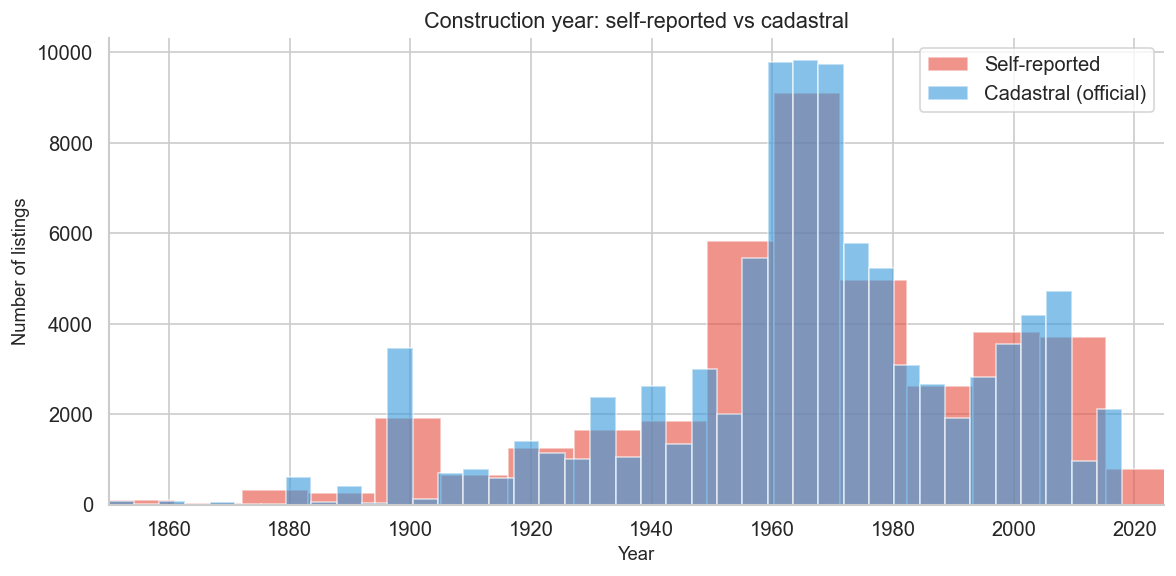

Note: 61 self-reported values below 1850 (erroneous) are excluded from this plot.


In [4]:
# Compare self-reported vs cadastral year distributions
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(cy[cy >= 1850], bins=40, alpha=0.6, color="#e74c3c", label="Self-reported", edgecolor="white")
ax.hist(df["CADCONSTRUCTIONYEAR"][df["CADCONSTRUCTIONYEAR"] >= 1850], bins=40, alpha=0.6,
        color="#3498db", label="Cadastral (official)", edgecolor="white")
ax.set_xlim(1850, 2025)
ax.set_xlabel("Year")
ax.set_ylabel("Number of listings")
ax.set_title("Construction year: self-reported vs cadastral")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

erroneous = cy[cy < 1850]
print(f"Note: {len(erroneous)} self-reported values below 1850 (erroneous) are excluded from this plot.")

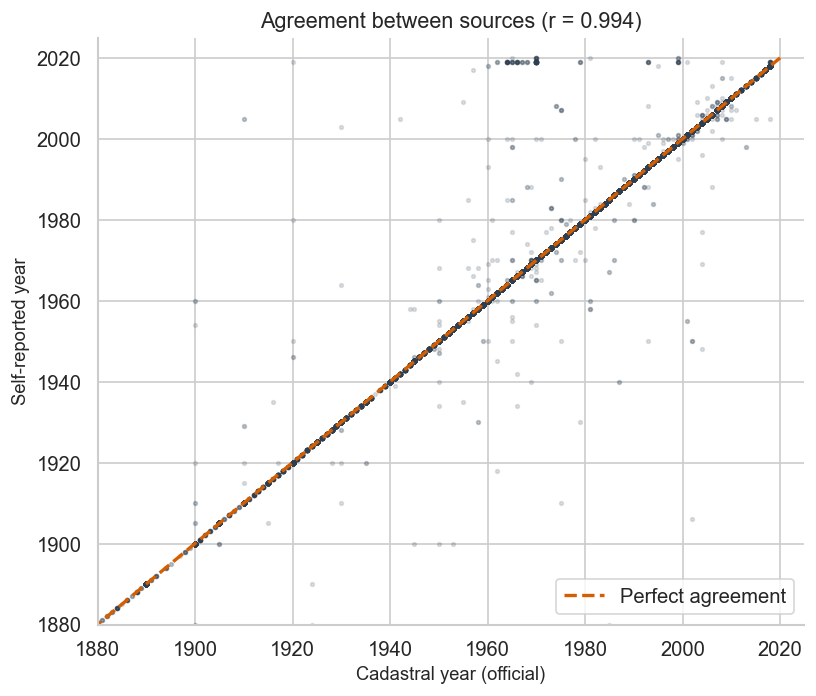

In [5]:
# How well do the two sources agree?
valid = df[df["CONSTRUCTIONYEAR"].between(1850, 2020)]
corr = valid["CONSTRUCTIONYEAR"].corr(valid["CADCONSTRUCTIONYEAR"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(valid["CADCONSTRUCTIONYEAR"], valid["CONSTRUCTIONYEAR"], alpha=0.15, s=5, color="#2c3e50")
ax.plot([1850, 2020], [1850, 2020], "r--", lw=2, label="Perfect agreement")
ax.set_xlim(1880, 2025)
ax.set_ylim(1880, 2025)
ax.set_xlabel("Cadastral year (official)")
ax.set_ylabel("Self-reported year")
ax.set_title(f"Agreement between sources (r = {corr:.3f})")
ax.legend(frameon=True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Decision: drop CONSTRUCTIONYEAR.

The cadastral source CADCONSTRUCTIONYEAR is complete, official, and highly correlated with the valid self-reported values. Keeping the self-reported column would force us to either impute 59% of the data, introducing noise into the model, or discard those rows, losing more than half the training set.

In [6]:
df = df.drop(columns=["CONSTRUCTIONYEAR"])
print(f"Dropped CONSTRUCTIONYEAR. Shape: {df.shape}")

Dropped CONSTRUCTIONYEAR. Shape: (94815, 40)


### 1.2 FLATLOCATIONID — 6.7% missing

This column indicates the flat position in the building: external (1) or internal (2). Missing values likely mean the information was not provided in the listing. Before deciding how to handle them, we check whether the missingness is random or carries information about price.

In [7]:
print(df["FLATLOCATIONID"].value_counts(dropna=False))
print(f"\nMedian PRICE by FLATLOCATIONID:")
print(df.groupby("FLATLOCATIONID", dropna=False)["PRICE"].median())

FLATLOCATIONID
1.0    76324
2.0    12104
NaN     6387
Name: count, dtype: int64

Median PRICE by FLATLOCATIONID:
FLATLOCATIONID
1.0    280000.0
2.0    241000.0
NaN    173000.0
Name: PRICE, dtype: float64


External flats have a higher median price (280,000 EUR) than internal ones (241,000 EUR). Missing values have a clearly different median price (173,000 EUR) from both groups, so the missingness is not random — it behaves as a separate category.

Decision: fill NaN with 0 to create an "unknown" category.

Imputing with the mode (1) would erase this price signal. Dropping 6,387 rows would reduce the training set unnecessarily. By encoding "unknown" as 0, the model can learn the distinct pricing pattern of these listings.

In [8]:
df["FLATLOCATIONID"] = df["FLATLOCATIONID"].fillna(0).astype(int)
print(df["FLATLOCATIONID"].value_counts())

FLATLOCATIONID
1    76324
2    12104
0     6387
Name: count, dtype: int64


### 1.3 FLOORCLEAN — 4.1% missing

The floor number of the flat. The value -1 appears 936 times and represents basement or ground-level units. We investigate whether the missing values are random or correlated with specific property types.

In [9]:
print(df["FLOORCLEAN"].value_counts(dropna=False).sort_index())

missing_floor = df["FLOORCLEAN"].isna()
check_cols = ["BUILTTYPEID_1", "BUILTTYPEID_2", "BUILTTYPEID_3", "HASGARDEN", "HASSWIMMINGPOOL"]
comparison = pd.DataFrame({
    "Missing floor": df.loc[missing_floor, check_cols].mean(),
    "All listings": df[check_cols].mean(),
}).round(3)
comparison.index = ["New development", "Second hand, to restore", "Second hand, good condition",
                    "Has garden", "Has swimming pool"]
display(comparison)

print(f"Median price – missing floor: {df.loc[missing_floor, 'PRICE'].median():,.0f} € | "
      f"all listings: {df['PRICE'].median():,.0f} €")

FLOORCLEAN
-1.0       936
 0.0     10112
 1.0     20336
 2.0     17044
 3.0     14754
 4.0     11635
 5.0      6162
 6.0      3733
 7.0      2447
 8.0      1495
 9.0       814
 10.0      450
 11.0     1051
 NaN      3846
Name: count, dtype: int64


,Missing floor,All listings
New development,0.218,0.030
"Second hand, to restore",0.189,0.187
"Second hand, good condition",0.593,0.783
Has garden,0.234,0.185
Has swimming pool,0.262,0.148


Median price – missing floor: 238,000 € | all listings: 262,000 €


Missing floors are not random: 21.8% of them are new developments (vs 3.0% overall), and they have more gardens and swimming pools. These are likely houses or new-build complexes where the floor number does not apply.

Decision: fill with the median (2) and create a FLOOR_MISSING indicator.

The median imputation allows the model to use FLOORCLEAN without losing rows. The binary indicator FLOOR_MISSING preserves the information that the floor was not reported, which is itself predictive since these are a distinct property type with different pricing.

In [10]:
df["FLOOR_MISSING"] = missing_floor.astype(int)
median_floor = df["FLOORCLEAN"].median()
df["FLOORCLEAN"] = df["FLOORCLEAN"].fillna(median_floor)
print(f"Created FLOOR_MISSING ({df['FLOOR_MISSING'].sum():,} listings) and filled FLOORCLEAN with median = {median_floor:.0f}")

Created FLOOR_MISSING (3,846 listings) and filled FLOORCLEAN with median = 2


### 1.4 CADASTRALQUALITYID — 1 missing

Only one row has a missing value. We fill it with the mode since a single imputation has no measurable impact on the model.

In [11]:
mode_quality = df["CADASTRALQUALITYID"].mode()[0]
df["CADASTRALQUALITYID"] = df["CADASTRALQUALITYID"].fillna(mode_quality)
print(f"Filled 1 missing value with mode = {mode_quality}")

Filled 1 missing value with mode = 4.0


## 2. Erroneous values

### 2.1 Extreme ROOMNUMBER and BATHNUMBER

We check whether listings with unusually high room or bathroom counts are real luxury properties or data entry errors.

In [12]:
extreme = df[(df["ROOMNUMBER"] > 10) | (df["BATHNUMBER"] > 5)]
print(f"Listings with more than 10 bedrooms or more than 5 bathrooms: {len(extreme)}")
print(extreme[["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]].describe().round(0))
print(f"\nShare with more than 300 m2: {(extreme['CONSTRUCTEDAREA'] > 300).mean():.0%}")

# Identify impossible listings: less than 10 m2 per bedroom
m2_per_room = df["CONSTRUCTEDAREA"] / df["ROOMNUMBER"].replace(0, np.nan)
impossible = m2_per_room < 10
print(f"\nListings with less than 10 m2 per bedroom: {impossible.sum()}")
display(df.loc[impossible, ["ROOMNUMBER", "BATHNUMBER", "CONSTRUCTEDAREA", "PRICE"]])

Listings with more than 10 bedrooms or more than 5 bathrooms: 288
       ROOMNUMBER  BATHNUMBER  CONSTRUCTEDAREA      PRICE
count       288.0       288.0            288.0      288.0
mean          8.0         7.0            428.0  2342069.0
std           6.0         2.0            200.0  1609089.0
min           4.0         1.0             90.0   109000.0
25%           6.0         6.0            260.0  1197500.0
50%           6.0         6.0            400.0  1947000.0
75%           9.0         7.0            558.0  2912500.0
max          93.0        20.0            982.0  8133000.0

Share with more than 300 m2: 68%

Listings with less than 10 m2 per bedroom: 9


,ROOMNUMBER,BATHNUMBER,CONSTRUCTEDAREA,PRICE
1645,3,0,25,119000.0
7524,3,1,25,54000.0
14134,3,1,28,80000.0
14164,3,1,28,69000.0
17638,93,2,119,450000.0
33410,3,1,28,103000.0
49815,3,1,28,59000.0
75514,6,1,55,188000.0
84059,33,2,90,109000.0


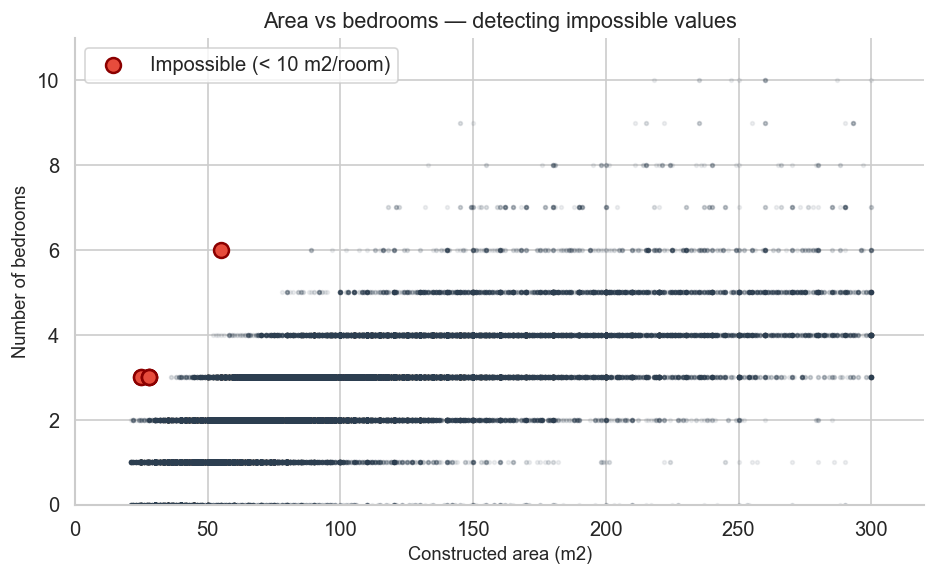

In [13]:
# Focus on the range where most data lives
normal = df[(df["ROOMNUMBER"] <= 10) & (df["CONSTRUCTEDAREA"] <= 300)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(normal["CONSTRUCTEDAREA"], normal["ROOMNUMBER"], alpha=0.08, s=5, color="#2c3e50")
ax.scatter(df.loc[impossible, "CONSTRUCTEDAREA"], df.loc[impossible, "ROOMNUMBER"],
           color="#e74c3c", s=80, zorder=5, edgecolors="darkred", linewidths=1.5,
           label="Impossible (< 10 m2/room)")
ax.set_xlim(0, 320)
ax.set_ylim(0, 11)
ax.set_xlabel("Constructed area (m2)")
ax.set_ylabel("Number of bedrooms")
ax.set_title("Area vs bedrooms — detecting impossible values")
ax.legend(frameon=True, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The 288 listings with more than 10 bedrooms or more than 5 bathrooms have a median area of 400 m2 and a median price of 1.9 million EUR. 68% of them exceed 300 m2. These are real luxury properties, not data entry errors. Capping them would remove valid high-end observations that the model needs to learn from.

A more reliable criterion is the area per bedroom: only 9 listings have less than 10 m2 per bedroom (for example 93 bedrooms in 119 m2), which is physically impossible. These are clear data entry errors.

Decision: remove only the 9 impossible listings (0.01% of the data). Large properties are kept because they represent the upper tail of the price distribution and are essential for the model to generalise across the full price range.

In [14]:
n_before = len(df)
df = df[~impossible]
print(f"Removed {n_before - len(df)} listings with an impossible number of bedrooms. Shape: {df.shape}")

Removed 9 listings with an impossible number of bedrooms. Shape: (94806, 41)


### 2.2 PARKINGSPACEPRICE inconsistency

In [15]:
for has_parking in [0, 1]:
    s = df.loc[df["HASPARKINGSPACE"] == has_parking, "PARKINGSPACEPRICE"]
    print(f"HASPARKINGSPACE = {has_parking}: {len(s):,} listings, "
          f"{(s == 1).mean():.1%} with PARKINGSPACEPRICE = 1")
    print(s.value_counts().head(5), "\n")

HASPARKINGSPACE = 0: 73,465 listings, 97.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1        71282
20001      230
30001      209
25001      185
15001      182
Name: count, dtype: int64 

HASPARKINGSPACE = 1: 21,341 listings, 100.0% with PARKINGSPACEPRICE = 1
PARKINGSPACEPRICE
1         21333
50001         1
15001         1
20001         1
220001        1
Name: count, dtype: int64 



PARKINGSPACEPRICE equals 1 (a placeholder) in 97-100% of listings regardless of whether the property has parking. The column carries no real information for the model.

Decision: drop PARKINGSPACEPRICE. Parking information is already captured by HASPARKINGSPACE and ISPARKINGSPACEINCLUDEDINPRICE, which are clean binary features.

In [16]:
df = df.drop(columns=["PARKINGSPACEPRICE"])
print(f"Dropped PARKINGSPACEPRICE. Shape: {df.shape}")

Dropped PARKINGSPACEPRICE. Shape: (94806, 40)


### 2.3 Geographic outlier

In [17]:
geo_outlier = df[df["LATITUDE"] < 40]
print(f"Listings with LATITUDE < 40: {len(geo_outlier)}")
print(geo_outlier[["LATITUDE", "LONGITUDE", "PRICE", "CONSTRUCTEDAREA"]])

Listings with LATITUDE < 40: 1
        LATITUDE  LONGITUDE     PRICE  CONSTRUCTEDAREA
84000  36.756391  -2.753303  191000.0              145


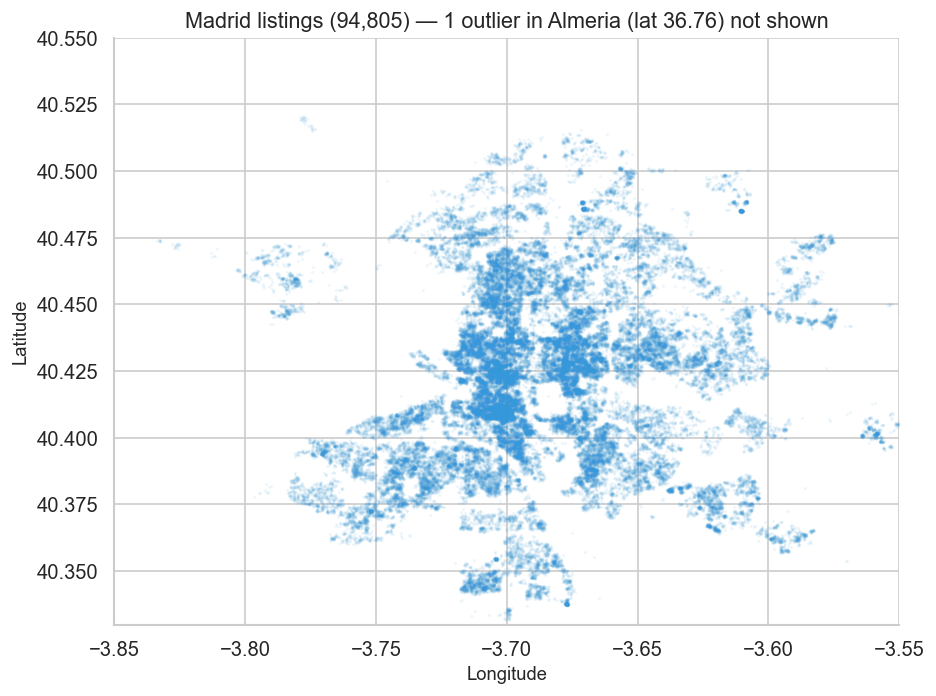

In [18]:
# Show Madrid listings only — the outlier is too far away to fit in the same axes
madrid = df[df["LATITUDE"] >= 40]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(madrid["LONGITUDE"], madrid["LATITUDE"], alpha=0.05, s=1, color="#3498db")
ax.set_xlim(-3.85, -3.55)
ax.set_ylim(40.33, 40.55)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(f"Madrid listings ({len(madrid):,}) — 1 outlier in Almeria (lat 36.76) not shown")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

One listing has coordinates in Almeria (latitude 36.76), far outside Madrid (latitude around 40.4). This is a geocoding error that would distort distance-based features and spatial patterns in the model.

Decision: remove this row. A single mislocated observation could disproportionately affect spatial features during training.

In [19]:
df = df[df["LATITUDE"] >= 40]
print(f"Removed geographic outlier. Shape: {df.shape}")

Removed geographic outlier. Shape: (94805, 40)


### 2.4 Duplicate listings

In [20]:
print(f"Total rows: {len(df):,}")
print(f"Unique ASSETIDs: {df['ASSETID'].nunique():,}")
print(f"Repeated rows: {len(df) - df['ASSETID'].nunique():,}")

Total rows: 94,805
Unique ASSETIDs: 75,795
Repeated rows: 19,010


In [21]:
# Investigate duplicates
dups = df[df.duplicated("ASSETID", keep=False)]
g = dups.groupby("ASSETID")

same_flat = ((g["CONSTRUCTEDAREA"].nunique() == 1) & (g["ROOMNUMBER"].nunique() == 1)
             & ((g["LATITUDE"].max() - g["LATITUDE"].min()) < 0.001))
price_changes = g["PRICE"].nunique() > 1
price_spread = g["PRICE"].max() / g["PRICE"].min() - 1

print(f"Repeated properties: {g.ngroups:,}")
print(f"Same area, bedrooms and location: {same_flat.mean():.1%}")
print(f"With different prices: {price_changes.mean():.1%}")
print(f"Median price spread: {price_spread.median():.1%}")

Repeated properties: 13,828
Same area, bedrooms and location: 90.8%
With different prices: 97.9%
Median price spread: 4.4%


Repeated ASSETIDs are the same property listed multiple times within the same quarter with slightly different prices (median gap of 4.4%). No property appears across multiple quarters — these are price updates of the same listing, not different properties.

Keeping all rows would violate the independence assumption: the model would see the same flat as several independent observations, inflating its confidence and biasing the training set toward re-listed properties.

Decision: keep one row per property with its median price. The median is robust to the occasional large price change and represents the central asking price during the quarter.

In [22]:
n_before = len(df)
df["PRICE"] = df.groupby("ASSETID")["PRICE"].transform("median")
df = df.drop_duplicates(subset=["ASSETID"], keep="first")
print(f"Kept one row per property with its median price. Removed {n_before - len(df):,} rows. Shape: {df.shape}")

Kept one row per property with its median price. Removed 19,010 rows. Shape: (75795, 40)


### 2.5 Target leakage: UNITPRICE

UNITPRICE is exactly PRICE divided by CONSTRUCTEDAREA (demonstrated in notebook 00). Including it as a feature would give the model direct access to the target variable, resulting in artificially perfect predictions during training that would not generalise to new data.

In [23]:
# Leakage already demonstrated in notebook 00 on the original data:
# UNITPRICE == PRICE / CONSTRUCTEDAREA (max difference 6.4e-12).
df = df.drop(columns=["UNITPRICE"])
print(f"Dropped UNITPRICE (target leakage). Shape: {df.shape}")

Dropped UNITPRICE (target leakage). Shape: (75795, 39)


## Summary

| Issue | Evidence | Action | Impact on modelling |
|---|---|---|---|
| CONSTRUCTIONYEAR — 59% missing | Erroneous values (1, 50, 2291); cadastral year is complete | Dropped (use CADCONSTRUCTIONYEAR) | Avoids imputing 59% of a feature; cadastral source is more reliable |
| FLATLOCATIONID — 6.7% missing | Missing values have distinct median price (173k vs 280k EUR) | Filled with 0 (unknown) | Preserves informative missingness as a category |
| FLOORCLEAN — 4.1% missing | Not random: 21.8% new developments vs 3.0% overall | Filled with median + FLOOR_MISSING indicator | Keeps all rows; indicator captures property-type signal |
| CADASTRALQUALITYID — 1 missing | Single row | Filled with mode | Negligible impact |
| 9 listings with impossible room counts | Less than 10 m2 per bedroom | Removed | Prevents the model from learning from corrupted data |
| PARKINGSPACEPRICE — placeholder values | Equals 1 in 97-100% of all listings | Dropped | Removes a non-informative feature |
| Geographic outlier in Almeria | Latitude 36.76 instead of around 40.4 | Removed | Prevents distortion of spatial features |
| 19,010 duplicate listings | Same flat, same quarter, different prices | One row per property with median price | Ensures observation independence for training |
| UNITPRICE = PRICE / AREA | Direct target leakage | Dropped | Prevents data leakage into the model |

Result: 75,795 unique properties with 39 clean columns, ready for distribution analysis and outlier treatment in notebook 02.

In [24]:
import os
os.makedirs("../data/processed", exist_ok=True)
df.to_parquet("../data/processed/listings_01.parquet", index=False)
print(f"Saved: {df.shape[0]} rows × {df.shape[1]} columns")

Saved: 75795 rows × 39 columns
